In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sbs
import numpy as np


df = pd.read_csv("vgsales.csv")

print(df.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  object 
 2   Platform      16598 non-null  object 
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  object 
 5   Publisher     16540 non-null  object 
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), object(4)
memory usage: 1.4+ MB
None


In [3]:
df.describe()

,Rank,Year,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
count,16598.000000,16327.000000,16598.000000,16598.000000,16598.000000,16598.000000,16598.000000
mean,8300.605254,2006.406443,0.264667,0.146652,0.077782,0.048063,0.537441
std,4791.853933,5.828981,0.816683,0.505351,0.309291,0.188588,1.555028
min,1.000000,1980.000000,0.000000,0.000000,0.000000,0.000000,0.010000
25%,4151.250000,2003.000000,0.000000,0.000000,0.000000,0.000000,0.060000
50%,8300.500000,2007.000000,0.080000,0.020000,0.000000,0.010000,0.170000
75%,12449.750000,2010.000000,0.240000,0.110000,0.040000,0.040000,0.470000
max,16600.000000,2020.000000,41.490000,29.020000,10.220000,10.570000,82.740000


In [ ]:
print("Genres")
print(df["Genre"].unique())
print("Platforms")
print(df["Platform"].unique())
print("Publishers")
print(df["Publisher"].unique())



Genres
['Sports' 'Platform' 'Racing' 'Role-Playing' 'Puzzle' 'Misc' 'Shooter'
 'Simulation' 'Action' 'Fighting' 'Adventure' 'Strategy']
Platforms
['Wii' 'NES' 'GB' 'DS' 'X360' 'PS3' 'PS2' 'SNES' 'GBA' '3DS' 'PS4' 'N64'
 'PS' 'XB' 'PC' '2600' 'PSP' 'XOne' 'GC' 'WiiU' 'GEN' 'DC' 'PSV' 'SAT'
 'SCD' 'WS' 'NG' 'TG16' '3DO' 'GG' 'PCFX']
Publishers
['Nintendo' 'Microsoft Game Studios' 'Take-Two Interactive'
 'Sony Computer Entertainment' 'Activision' 'Ubisoft' 'Bethesda Softworks'
 'Electronic Arts' 'Sega' 'SquareSoft' 'Atari' '505 Games' 'Capcom'
 'GT Interactive' 'Konami Digital Entertainment'
 'Sony Computer Entertainment Europe' 'Square Enix' 'LucasArts'
 'Virgin Interactive' 'Warner Bros. Interactive Entertainment'
 'Universal Interactive' 'Eidos Interactive' 'RedOctane' 'Vivendi Games'
 'Enix Corporation' 'Namco Bandai Games' 'Palcom' 'Hasbro Interactive'
 'THQ' 'Fox Interactive' 'Acclaim Entertainment' 'MTV Games'
 'Disney Interactive Studios' nan 'Majesco Entertainment' 'Codemasters'


In [ ]:
print(df["Genre"].value_counts())
print(df["Platform"].value_counts())


Genre
Action          3316
Sports          2346
Misc            1739
Role-Playing    1488
Shooter         1310
Adventure       1286
Racing          1249
Platform         886
Simulation       867
Fighting         848
Strategy         681
Puzzle           582
Name: count, dtype: int64
Platform
DS      2163
PS2     2161
PS3     1329
Wii     1325
X360    1265
PSP     1213
PS      1196
PC       960
XB       824
GBA      822
GC       556
3DS      509
PSV      413
PS4      336
N64      319
SNES     239
XOne     213
SAT      173
WiiU     143
2600     133
NES       98
GB        98
DC        52
GEN       27
NG        12
SCD        6
WS         6
3DO        3
TG16       2
GG         1
PCFX       1
Name: count, dtype: int64
Publisher
Electronic Arts                 1351
Activision                       975
Namco Bandai Games               932
Ubisoft                          921
Konami Digital Entertainment     832
                                ... 
Warp                               1
New      

In [16]:
print(df["Publisher"].value_counts())

Publisher
Electronic Arts                 1351
Activision                       975
Namco Bandai Games               932
Ubisoft                          921
Konami Digital Entertainment     832
                                ... 
Warp                               1
New                                1
Elite                              1
Evolution Games                    1
UIG Entertainment                  1
Name: count, Length: 578, dtype: int64


# Data Quality

In [21]:
missing_data = df.isna().sum()
missing_data

Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

In [27]:
print("Number of duplicated records")
print(df.duplicated().sum())

Number of duplicated records
0


In [60]:
unique_rank = df["Rank"].value_counts().sum()

print(unique_rank)




16598


In [61]:
total_sales = df["NA_Sales"].sum() + df["EU_Sales"].sum() + + df["JP_Sales"].sum() + df["Other_Sales"].sum()

print(total_sales)
print(df["Global_Sales"].sum())

8915.85
8920.44


# Popularity 

#### What are the top three genres in each market?

In [91]:
top_genres_eu = df["EU_Sales"].groupby(df["Genre"])

top_genres_na = df["NA_Sales"].groupby(df["Genre"])

top_genres_jp = df["JP_Sales"].groupby(df["Genre"])

top_genres_other = df["Other_Sales"].groupby(df["Genre"])


top_genres = pd.DataFrame({
    "EU Market" : top_genres_eu.sum().sort_values(ascending=False).head(7),
    "NA Market" : top_genres_na.sum().sort_values(ascending=False).head(7),
    "JP Market" : top_genres_jp.sum().sort_values(ascending=False).head(7),
    "Other markets" : top_genres_other.sum().sort_values(ascending=False).head(7)
})

top_genres.dropna(inplace=True)

print(top_genres)

              EU Market  NA Market  JP Market  Other markets
Genre                                                       
Action           525.00     877.83     159.95         187.38
Misc             215.98     410.24     107.76          75.32
Platform         201.63     447.05     130.77          51.59
Role-Playing     188.06     327.28     352.31          59.61
Sports           376.85     683.35     135.37         134.97


In [234]:
na = df.groupby("Genre")["NA_Sales"].sum().nlargest(5).index
navalues = df.groupby("Genre")["NA_Sales"].sum().nlargest(5).values
eu = df.groupby("Genre")["EU_Sales"].sum().nlargest(5).index

top = pd.DataFrame({
    "NA Market" : na,
    "NA Market1" : navalues
})
display(top)

,NA Market,NA Market1
0,Action,877.83
1,Sports,683.35
2,Shooter,582.60
3,Platform,447.05
4,Misc,410.24


In [239]:
na_market = pd.DataFrame({
    "NA Market": df.groupby("Genre")["NA_Sales"].sum().nlargest(5).index,
    "Sales NA Market": df.groupby("Genre")["NA_Sales"].sum().nlargest(5).values,
    "EU Market": df.groupby("Genre")["EU_Sales"].sum().nlargest(5).index,
    "Sales EU Market": df.groupby("Genre")["EU_Sales"].sum().nlargest(5).values,
    "JP Market" : df.groupby("Genre")["JP_Sales"].sum().nlargest(5).index,
    "Sales JP Market" : df.groupby("Genre")["JP_Sales"].sum().nlargest(5).values
})

display(na_market)

,NA Market,Sales NA Market,EU Market,Sales EU Market,JP Market,Sales JP Market
0,Action,877.83,Action,525.00,Role-Playing,352.31
1,Sports,683.35,Sports,376.85,Action,159.95
2,Shooter,582.60,Shooter,313.27,Sports,135.37
3,Platform,447.05,Racing,238.39,Platform,130.77
4,Misc,410.24,Misc,215.98,Misc,107.76


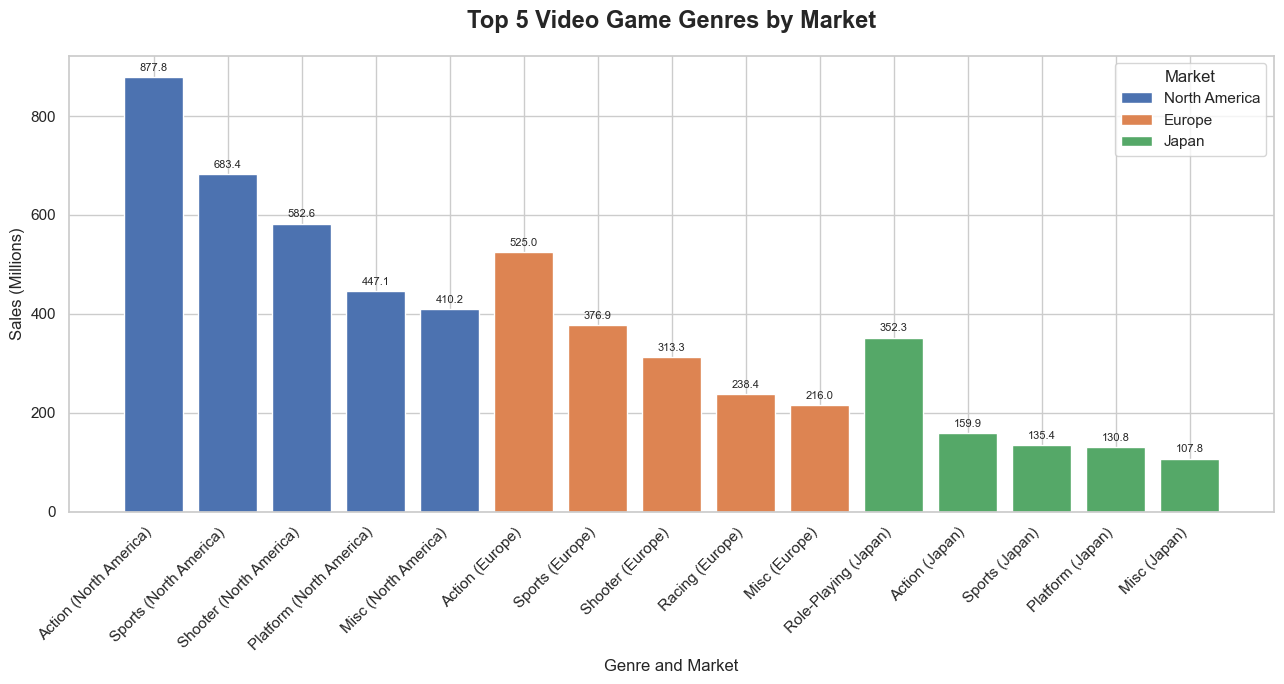

In [250]:

import pandas as pd
import matplotlib.pyplot as plt

# Combine the three markets
plot_data = pd.concat([
    pd.DataFrame({
        "Genre": na_market["NA Market"],
        "Sales": na_market["Sales NA Market"],
        "Market": "North America"
    }),
    pd.DataFrame({
        "Genre": na_market["EU Market"],
        "Sales": na_market["Sales EU Market"],
        "Market": "Europe"
    }),
    pd.DataFrame({
        "Genre": na_market["JP Market"],
        "Sales": na_market["Sales JP Market"],
        "Market": "Japan"
    })
])

# Create one grouped bar chart
fig, ax = plt.subplots(figsize=(13, 7))

for i, market in enumerate(plot_data["Market"].unique()):
    data = plot_data[plot_data["Market"] == market]

    bars = ax.bar(
        [f"{g} ({market})" for g in data["Genre"]],
        data["Sales"],
        label=market
    )

    ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=8)

ax.set_title("Top 5 Video Game Genres by Market",
             fontsize=17, fontweight="bold", pad=20)

ax.set_xlabel("Genre and Market")
ax.set_ylabel("Sales (Millions)")
ax.legend(title="Market")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()
